# QUESTION 1

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
import yfinance as yf

In [5]:
x = np.linspace(-10, 10, 300)

In [6]:
def f(x):
    return np.sqrt(2 * np.abs(x) - x**2)

In [7]:
def g(x):
    return -2.14 * np.sqrt(np.sqrt(2) - np.sqrt(np.abs(x)))

In [8]:
plt.figure(figsize=(10,5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

C:\Users\Emmanuel Ganyo\AppData\Local\Temp\ipykernel_12144\2257918533.py:2: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(2 * np.abs(x) - x**2)


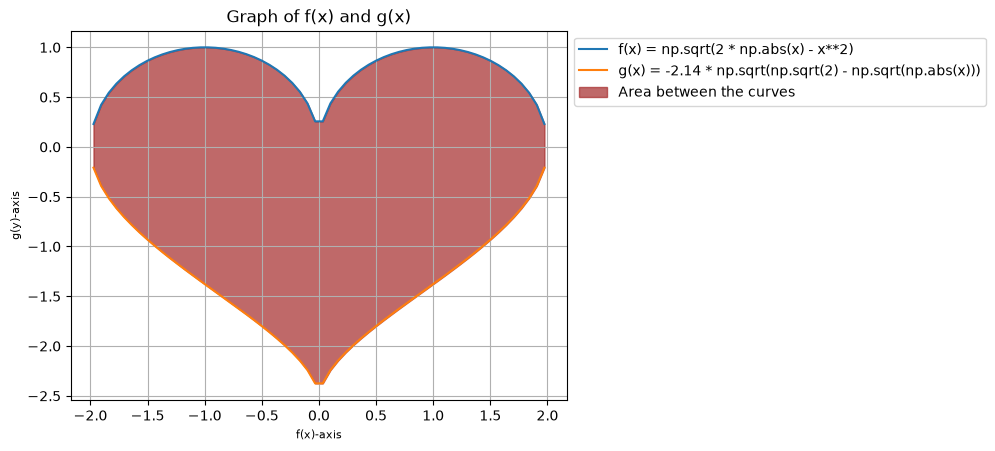

In [9]:
plt.plot(x, f(x), label = 'f(x) = np.sqrt(2 * np.abs(x) - x**2)')
plt.plot(x, g(x), label = 'g(x) = -2.14 * np.sqrt(np.sqrt(2) - np.sqrt(np.abs(x)))')
plt.fill_between(x, f(x), g(x), label = 'Area between the curves', color = 'brown', alpha = 0.7)
plt.xlabel('f(x)-axis', fontsize = 8)
plt.ylabel('g(y)-axis', fontsize = 8)
plt.title('Graph of f(x) and g(x)', fontsize = 12)
plt.legend(loc = 'upper left', bbox_to_anchor = (1, 1))
plt.grid()
plt.show()

# QUESTION 2

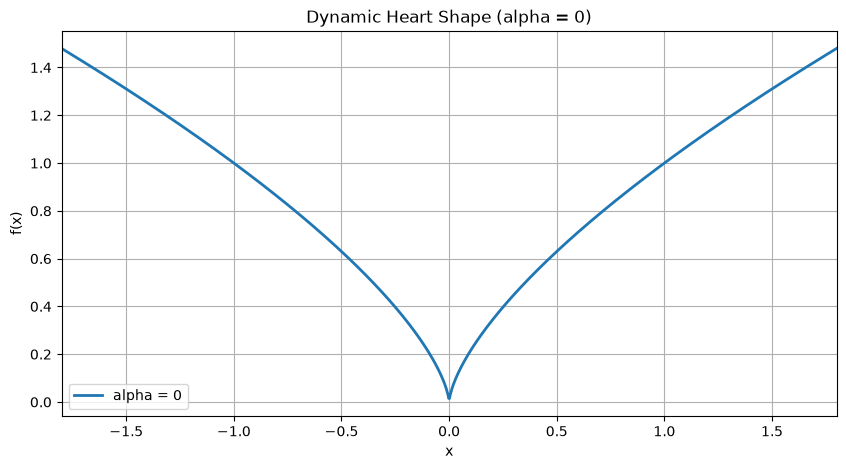

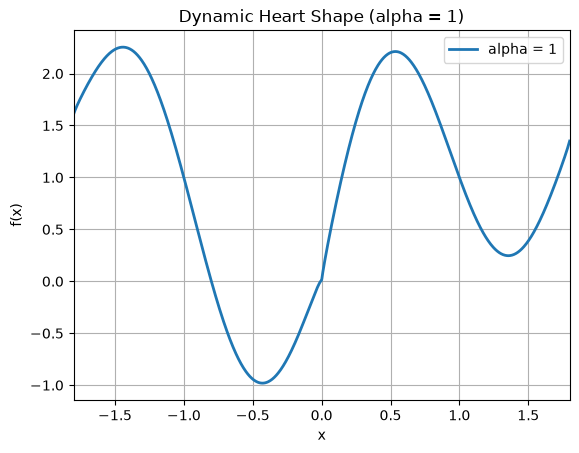

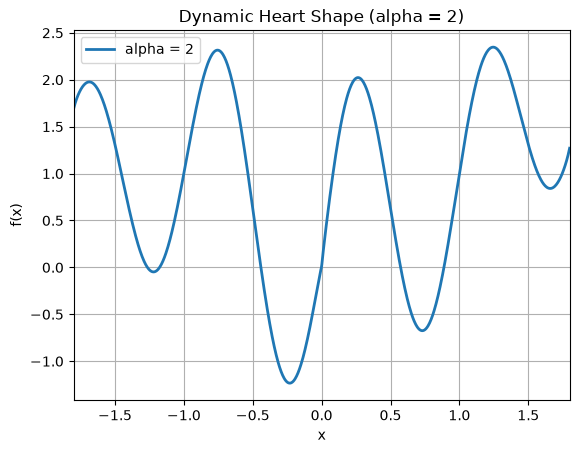

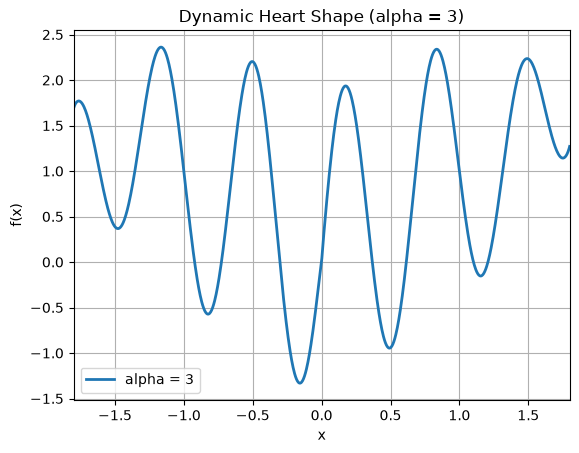

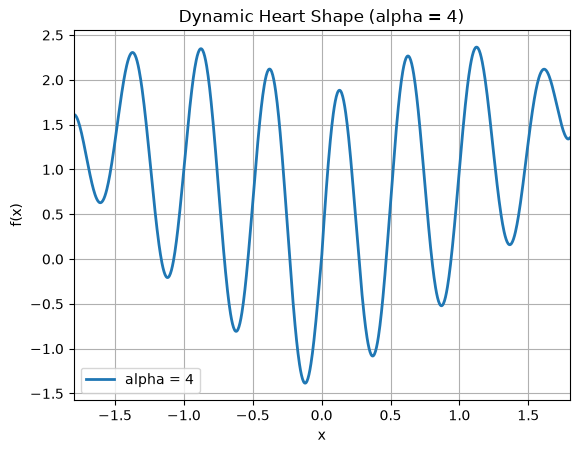

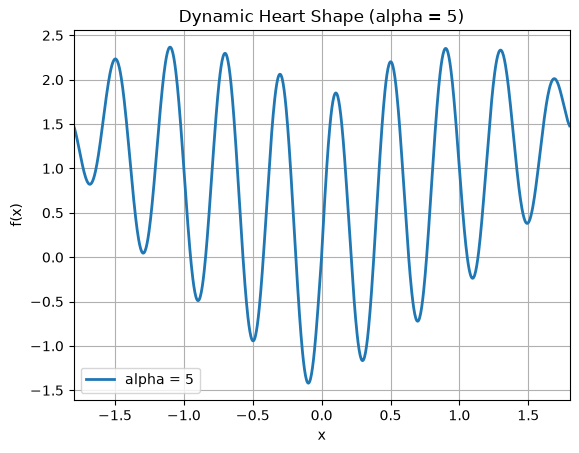

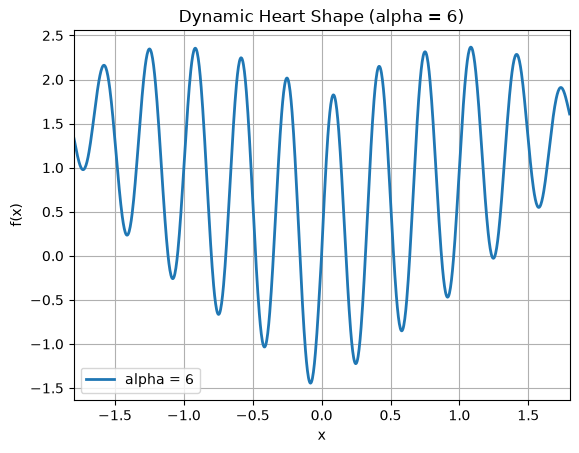

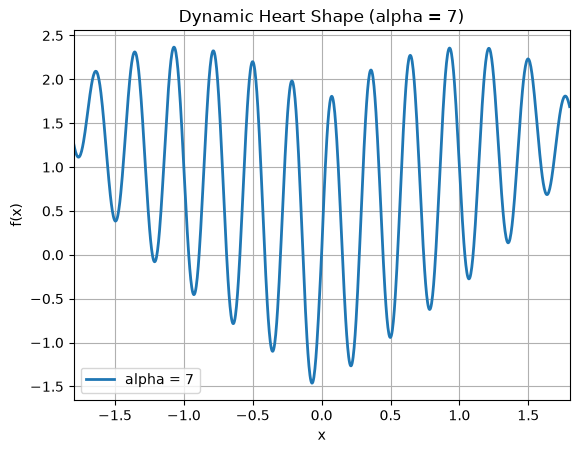

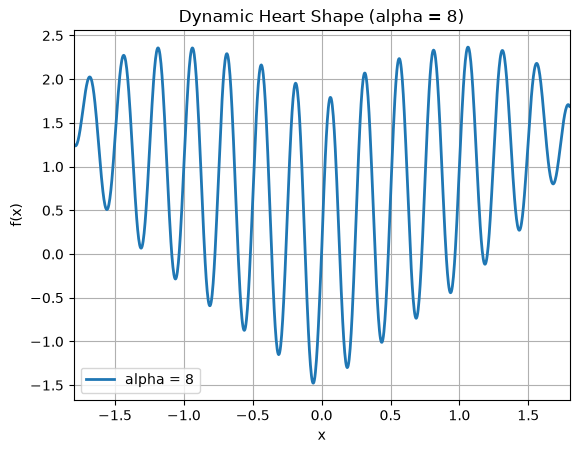

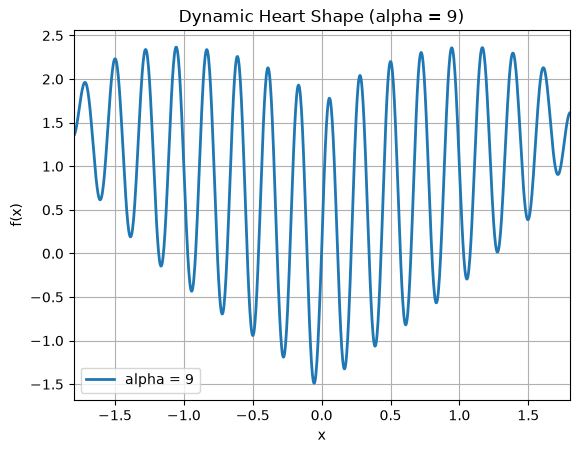

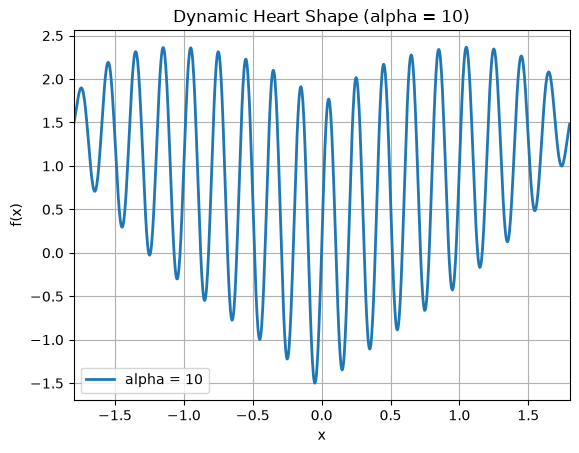

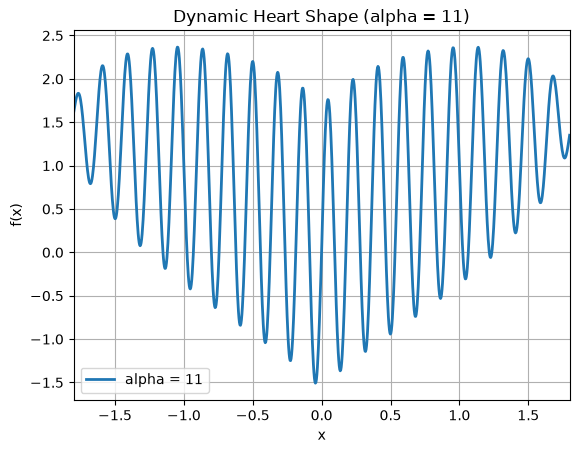

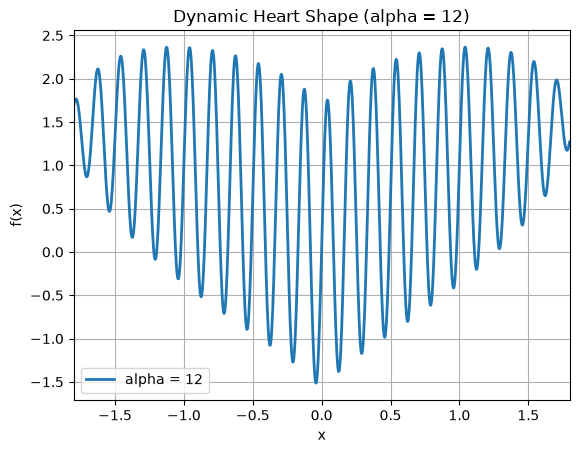

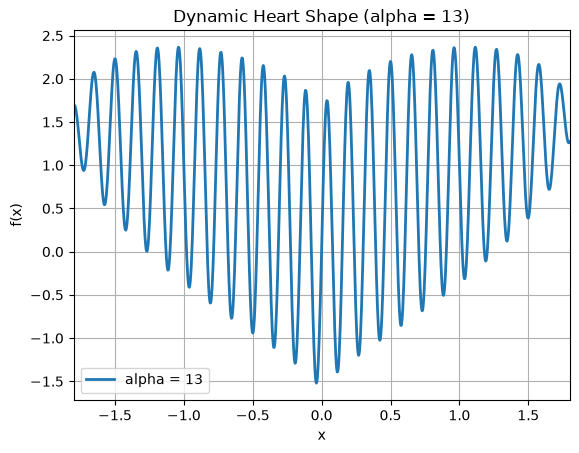

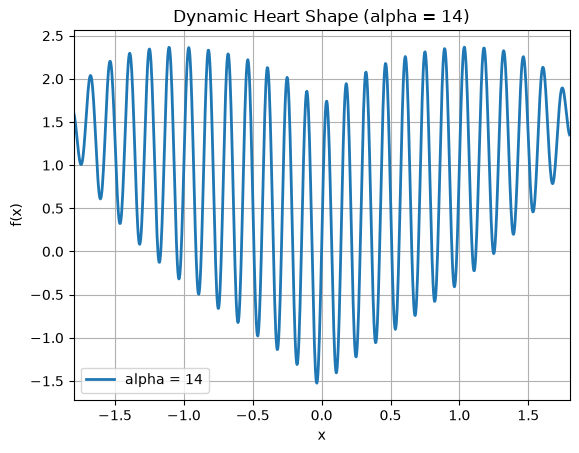

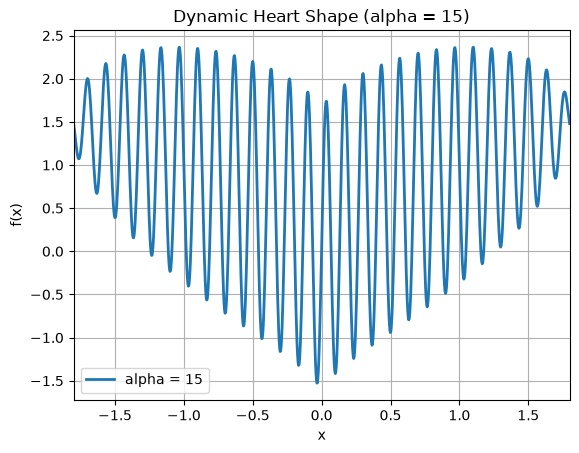

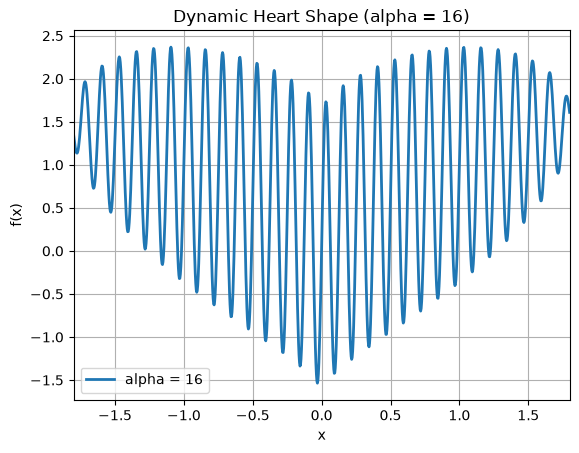

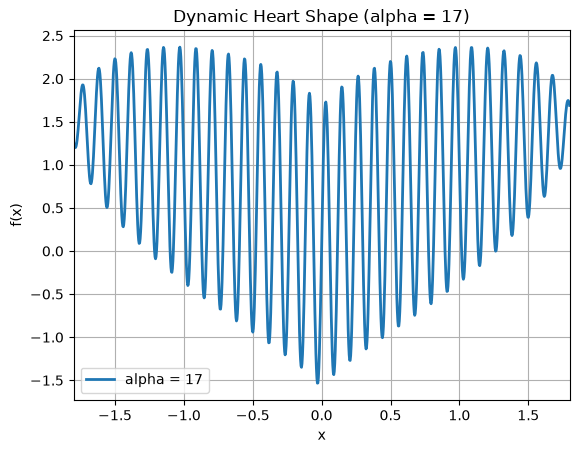

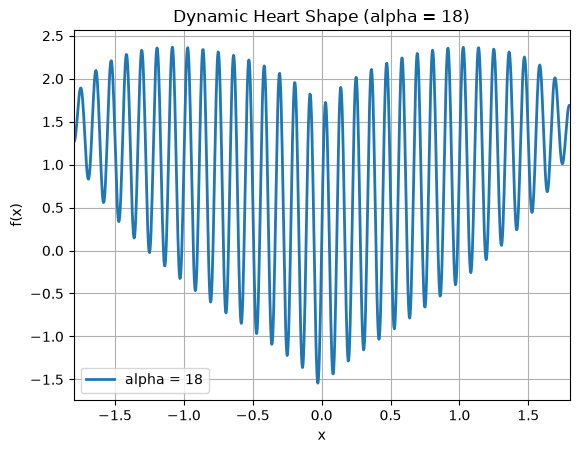

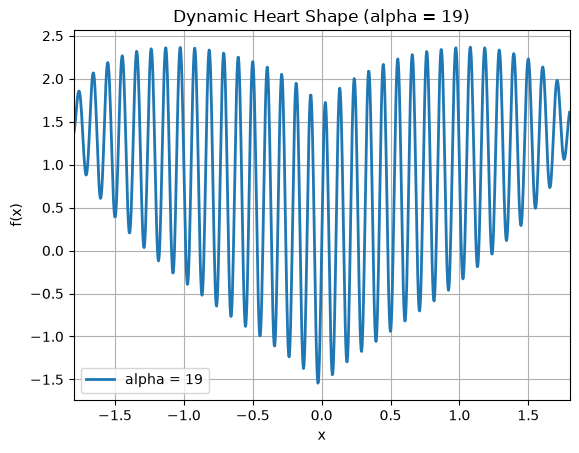

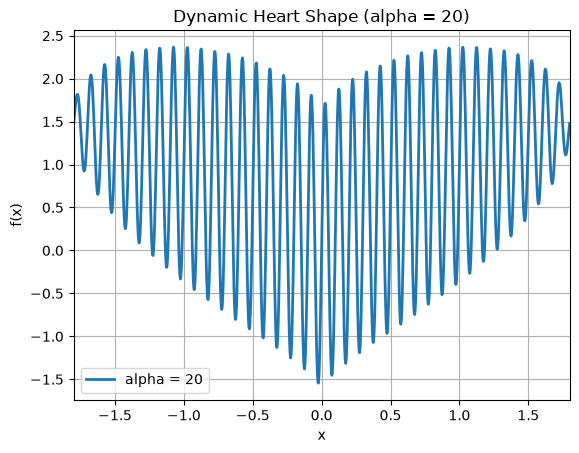

In [10]:
x = np.linspace(-1.8, 1.8, 1000)

plt.ion()

plt.figure(figsize=(10, 5))

for alpha in range(21):

    y = (np.abs(x)**(2/3) + 0.9 * np.sqrt(3.3 - x**2) * np.sin(alpha * np.pi * x))

    plt.clf()

    plt.plot(x, y, linewidth=2, label=f"alpha = {alpha}")

    plt.title(f"Dynamic Heart Shape (alpha = {alpha})")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.xlim(-1.8, 1.8)
    plt.grid(True)
    plt.legend()
    plt.pause(0.3)

plt.ioff()
plt.show()


# QUESTION 3

In [11]:
data = {"Student_ID": ["DSE1", "DSE2", "DSE3", "DSE4", "DSE5","DSE6", "DSE7", "DSE8", "DSE9", "DSE10"],
"Student_Name": ["Godfred", "Emmanuel", "Joseph", "Lordina","Festus", "Atule", "Derrick", "Princess",
"Kenneth", "Christiana"],
    "Data Science": [85, 72, 45, 91, 67, 78, 88, 39, 74, 82],
    "Economics": [78, 65, 55, 84, 48, 73, 92, 61, 69, 80],
    "Statistics": [90, 76, 42, 87, 63, 81, 95, 54, 71, 89]}

transcripts = pd.DataFrame(data)

file_name = "student_transcripts.xlsx"

transcripts.to_excel(file_name, index=False, sheet_name="Transcripts")

print("Excel file created successfully:", file_name)

transcripts

Excel file created successfully: student_transcripts.xlsx


,Student_ID,Student_Name,Data Science,Economics,Statistics
0,DSE1,Godfred,85,78,90
1,DSE2,Emmanuel,72,65,76
2,DSE3,Joseph,45,55,42
3,DSE4,Lordina,91,84,87
4,DSE5,Festus,67,48,63
5,DSE6,Atule,78,73,81
6,DSE7,Derrick,88,92,95
7,DSE8,Princess,39,61,54
8,DSE9,Kenneth,74,69,71
9,DSE10,Christiana,82,80,89


In [12]:
df = pd.read_excel("student_transcripts.xlsx")
print("Original student transcripts:")
df

Original student transcripts:


,Student_ID,Student_Name,Data Science,Economics,Statistics
0,DSE1,Godfred,85,78,90
1,DSE2,Emmanuel,72,65,76
2,DSE3,Joseph,45,55,42
3,DSE4,Lordina,91,84,87
4,DSE5,Festus,67,48,63
5,DSE6,Atule,78,73,81
6,DSE7,Derrick,88,92,95
7,DSE8,Princess,39,61,54
8,DSE9,Kenneth,74,69,71
9,DSE10,Christiana,82,80,89


In [13]:
PASS_MARK = 50

In [14]:
course_columns = ["Data Science", "Economics", "Statistics"]
failed_mask = (df[course_columns] < PASS_MARK).any(axis=1)

In [15]:
passed_students = df.loc[~failed_mask].copy()
print("Students remaining after removing failures:")
passed_students

Students remaining after removing failures:


,Student_ID,Student_Name,Data Science,Economics,Statistics
0,DSE1,Godfred,85,78,90
1,DSE2,Emmanuel,72,65,76
3,DSE4,Lordina,91,84,87
5,DSE6,Atule,78,73,81
6,DSE7,Derrick,88,92,95
8,DSE9,Kenneth,74,69,71
9,DSE10,Christiana,82,80,89


In [16]:
failed_students = df.loc[failed_mask].copy()
print("Students with at least one failed course:")
failed_students

Students with at least one failed course:


,Student_ID,Student_Name,Data Science,Economics,Statistics
2,DSE3,Joseph,45,55,42
4,DSE5,Festus,67,48,63
7,DSE8,Princess,39,61,54


In [17]:
average_grades = passed_students[course_columns].mean()

In [18]:
highest_grades = passed_students[course_columns].max()

In [19]:
course_summary = pd.DataFrame({"Average Grade": average_grades,"Highest Grade": highest_grades})
print("Average and highest grades for each course:")
course_summary

Average and highest grades for each course:


,Average Grade,Highest Grade
Data Science,81.428571,91
Economics,77.285714,92
Statistics,84.142857,95


In [20]:
course_summary["Rank"] = (course_summary["Average Grade"] .rank(method="min", ascending=False).astype(int))

In [21]:
course_ranking = course_summary.sort_values(by=["Average Grade"], ascending=False)
print("Course ranking based on average grades:")
course_ranking

Course ranking based on average grades:


,Average Grade,Highest Grade,Rank
Statistics,84.142857,95,1
Data Science,81.428571,91,2
Economics,77.285714,92,3


In [22]:
output_file = "student_transcript_analysis.xlsx"

In [23]:
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Original Transcripts", index=False)

In [24]:
failed_students.to_excel(writer, sheet_name="Failed Students", index=False)

In [25]:
passed_students.to_excel(writer, sheet_name="Passed Students", index=False)

In [26]:
course_ranking.to_excel(writer, sheet_name="Course Rankings")

In [27]:
print("Analysis completed.")
print("Results saved to:", output_file)

Analysis completed.
Results saved to: student_transcript_analysis.xlsx


# QUESTION 4

In [28]:
companies = pd.DataFrame({"Ticker": ["BA", "GD", "RTX", "LMT", "NOC","LLY", "JNJ", "ABBV", "AMGN", "GILD", "PFE", "BMY", "XOM", "CVX", "OXY", "SLB", "HAL", "KO"],"Company": 
        ["Boeing", "General Dynamics", "RTX Corporation (Raytheon)", "Lockheed Martin", "Northrop Grumman", "Eli Lilly and Company",
        "Johnson & Johnson", "AbbVie Inc.", "Amgen Inc.", "Gilead Sciences, Inc.", "Pfizer Inc.",
        "Bristol Myers Squibb", "ExxonMobil", "Chevron", "Occidental Petroleum", "Schlumberger / SLB", "Halliburton", "Coca-Cola"],"Industry": 
        ["Defence", "Defence", "Defence", "Defence", "Defence",
        "Pharmaceuticals", "Pharmaceuticals", "Pharmaceuticals", "Pharmaceuticals", "Pharmaceuticals", "Pharmaceuticals", "Pharmaceuticals",
        "Oil and Gas", "Oil and Gas", "Oil and Gas", "Oil and Gas Services", "Oil and Gas Services",
        "Soft Drinks"]})

In [29]:
companies

,Ticker,Company,Industry
0,BA,Boeing,Defence
1,GD,General Dynamics,Defence
2,RTX,RTX Corporation (Raytheon),Defence
3,LMT,Lockheed Martin,Defence
4,NOC,Northrop Grumman,Defence
5,LLY,Eli Lilly and Company,Pharmaceuticals
6,JNJ,Johnson & Johnson,Pharmaceuticals
7,ABBV,AbbVie Inc.,Pharmaceuticals
8,AMGN,Amgen Inc.,Pharmaceuticals
9,GILD,"Gilead Sciences, Inc.",Pharmaceuticals


In [30]:
tickers = companies["Ticker"].tolist()

start_date = "2022-01-01"
end_date = (pd.Timestamp.now(tz="UTC") .normalize() .tz_localize(None) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

raw_data = yf.download(tickers=tickers, start=start_date, end=end_date, interval="1d", auto_adjust=False, group_by="column", progress=True, threads=True)

[*********************100%***********************]  18 of 18 completed


In [31]:
if raw_data.empty:
    raise ValueError("No price data were downloaded. Check your internet connection "
        "and Yahoo Finance availability.")

if isinstance(raw_data.columns, pd.MultiIndex):
    if "Close" not in raw_data.columns.get_level_values(0):
        raise ValueError("The download did not contain a Close field.")

    closing_prices = raw_data["Close"].copy()
else:
    closing_prices = raw_data[["Close"]].copy()
    closing_prices.columns = [tickers[0]]

closing_prices = closing_prices.reindex(columns=tickers)
closing_prices = closing_prices.sort_index()
closing_prices = closing_prices.dropna(how="all")

print("Downloaded closing prices:")
print("Start date:", closing_prices.index.min())
print("End date:", closing_prices.index.max())
print("Number of observations:", len(closing_prices))
print("Number of tickers:", len(closing_prices.columns))

Downloaded closing prices:
Start date: 2022-01-03 00:00:00
End date: 2026-10-23 00:00:00
Number of observations: 1207
Number of tickers: 18


In [32]:
closing_prices.head()

Ticker,BA,GD,RTX,LMT,NOC,LLY,JNJ,ABBV,AMGN,GILD,PFE,BMY,XOM,CVX,OXY,SLB,HAL,KO
Date,,,,,,,,,,,,,,,,,,
2022-01-03,207.860001,207.460007,86.970001,354.359985,385.529999,271.730011,171.539993,135.419998,226.690002,72.580002,56.650002,61.880001,63.540001,119.260002,31.059999,31.719999,23.990000,59.299999
2022-01-04,213.630005,212.050003,90.019997,361.989990,396.989990,266.809998,171.080002,135.160004,227.839996,72.209999,54.529999,62.130001,65.930000,121.430000,33.380001,33.259998,25.430000,60.290001
2022-01-05,213.070007,210.309998,89.570000,358.140015,394.989990,260.649994,172.220001,135.869995,225.139999,72.180000,55.630001,62.160000,66.750000,122.220001,31.809999,33.259998,25.180000,60.790001
2022-01-06,211.339996,211.740005,90.059998,358.000000,397.269989,259.329987,171.630005,135.229996,225.169998,71.589996,54.840000,61.480000,68.320000,123.260002,32.759998,34.049999,25.610001,60.470001
2022-01-07,215.500000,212.089996,90.440002,360.140015,400.420013,259.500000,173.949997,134.880005,227.289993,71.260002,55.720001,62.830002,68.879997,125.029999,33.209999,35.029999,26.020000,60.330002


In [33]:
event_2022 = pd.Timestamp("2022-02-24")
event_2026 = pd.Timestamp("2026-02-28")

In [34]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

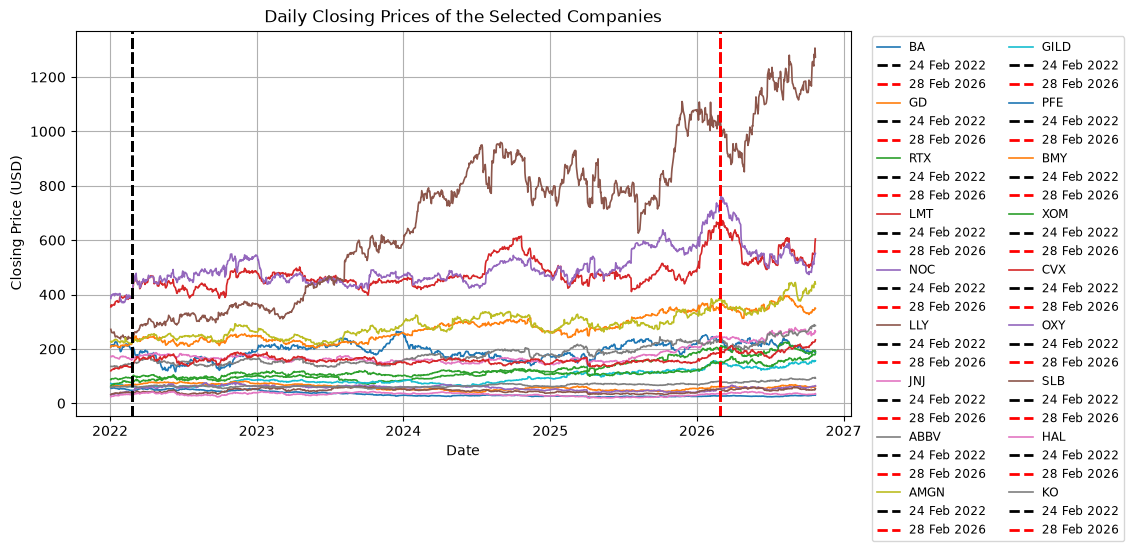

In [35]:
for ticker in closing_prices.columns:
    plt.plot(closing_prices.index, closing_prices[ticker], label=ticker, linewidth=1.2)
    plt.axvline(event_2022, color="black", linestyle="--", linewidth=2, label="24 Feb 2022")
    plt.axvline(event_2026, color="red", linestyle="--", linewidth=2, label="28 Feb 2026")

plt.title("Daily Closing Prices of the Selected Companies")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="small")
plt.grid(True)
plt.show()

In [56]:
# Q4d
# While price levels showed persistent outperfomance post-2022, log returns shows that the effect effect was transitory and volatility-driven. The Russia-Ukraine invasion generated differences in price levels, and varying degrees of volatility among companies,consitent with geopolitical risk shocks. Soft drinks exhibited low volatility and no abnormal returns around both situations, indicating its role as a defensive sector.

In [36]:
indexed_prices = (closing_prices .div(closing_prices.bfill().iloc[0]) .mul(100))

In [37]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

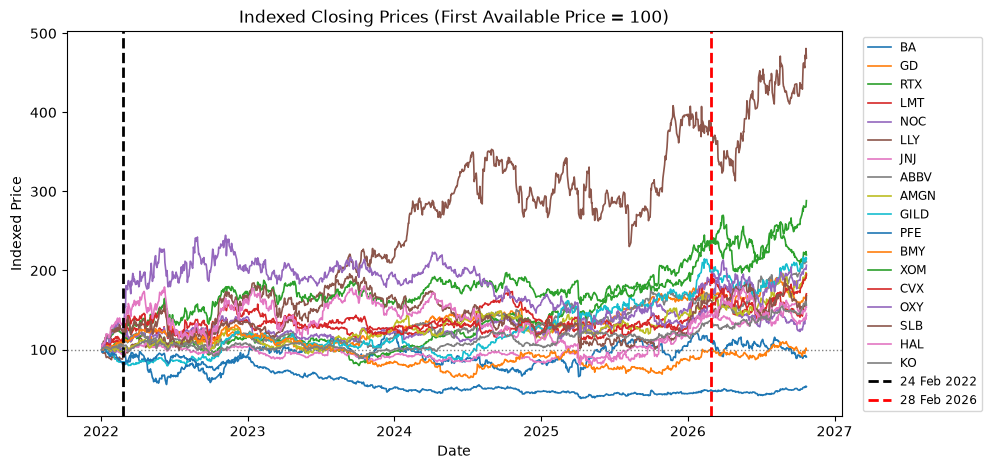

In [38]:
for ticker in indexed_prices.columns:
    plt.plot(indexed_prices.index, indexed_prices[ticker], label=ticker, linewidth=1.2)
plt.axvline(event_2022, color="black", linestyle="--", linewidth=2, label="24 Feb 2022")
plt.axvline(event_2026, color="red", linestyle="--", linewidth=2, label="28 Feb 2026")

plt.axhline(100, color="gray", linestyle=":", linewidth=1)

plt.title("Indexed Closing Prices (First Available Price = 100)")
plt.xlabel("Date")
plt.ylabel("Indexed Price")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=1, fontsize="small")
plt.show()

In [39]:
log_returns = np.log(closing_prices).diff().dropna(how="all")
print("Logarithmic returns:")

Logarithmic returns:


In [40]:
log_returns.head()
print("Number of return observations:", len(log_returns))

Number of return observations: 1206


In [41]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

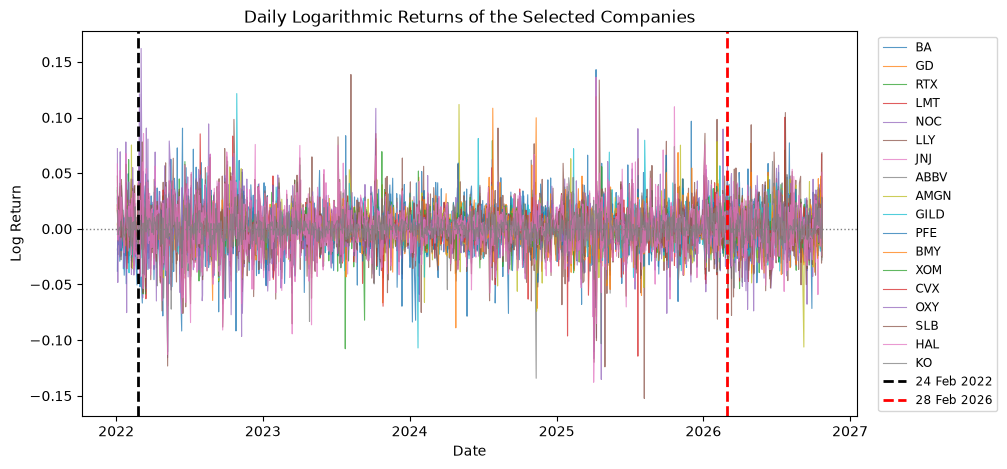

In [42]:
for ticker in log_returns.columns:
    plt.plot(log_returns.index, log_returns[ticker], label=ticker, linewidth=0.8, alpha=0.75)

plt.axvline(event_2022, color="black", linestyle="--", linewidth=2, label="24 Feb 2022")
plt.axvline(event_2026, color="red", linestyle="--", linewidth=2, label="28 Feb 2026")
plt.axhline(0, color="gray", linestyle=":", linewidth=1)

plt.title("Daily Logarithmic Returns of the Selected Companies")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=1, fontsize="small")
plt.show()

In [43]:
def event_window_analysis(returns, event_date, window=5):
    """Compare average company returns before and after an event date.
    The event date itself may not be a trading day.
    The pre-event window uses the last available sessions before
    the date; the post-event window uses sessions on or after it."""

    event_date = pd.Timestamp(event_date)
    before = returns.loc[returns.index < event_date].tail(window)
    after = returns.loc[returns.index >= event_date].head(window)

    if before.empty or after.empty:
        print(f"Insufficient data for event date {event_date.date()}.")
        return None

    result = pd.DataFrame({"Mean Return Before": before.mean(), "Mean Return After": after.mean(),
        "Difference (After - Before)": after.mean() - before.mean()})

    result["Mean Return Before"] = result["Mean Return Before"]
    result["Mean Return After"] = result["Mean Return After"]
    return result


for date in ["2022-02-24", "2026-02-28"]:
    print(f"\nEvent window analysis for {date}")

    event_results = event_window_analysis(log_returns, date, window=5)
    if event_results is not None:
        event_results


Event window analysis for 2022-02-24

Event window analysis for 2026-02-28


In [44]:
return_correlations = log_returns.corr(method="pearson")
print("Correlation matrix of daily log returns:")
return_correlations

Correlation matrix of daily log returns:


Ticker,BA,GD,RTX,LMT,NOC,LLY,JNJ,ABBV,AMGN,GILD,PFE,BMY,XOM,CVX,OXY,SLB,HAL,KO
Ticker,,,,,,,,,,,,,,,,,,
BA,1.000000,0.301403,0.363525,0.139973,0.156777,0.130135,0.060015,0.079509,0.120880,0.168686,0.169733,0.060869,0.126577,0.158707,0.144750,0.248636,0.238721,0.111002
GD,0.301403,1.000000,0.589685,0.599833,0.586472,0.194306,0.268904,0.231473,0.256584,0.227683,0.255082,0.226576,0.324137,0.334521,0.302433,0.345155,0.376925,0.271160
RTX,0.363525,0.589685,1.000000,0.524611,0.581529,0.186008,0.231363,0.209959,0.190999,0.230942,0.213786,0.212925,0.249158,0.246117,0.221718,0.259880,0.323848,0.247625
LMT,0.139973,0.599833,0.524611,1.000000,0.646593,0.113153,0.252950,0.157975,0.134011,0.172145,0.159514,0.178064,0.252961,0.250315,0.227706,0.231442,0.226671,0.246748
NOC,0.156777,0.586472,0.581529,0.646593,1.000000,0.131841,0.277598,0.153937,0.164436,0.188134,0.177254,0.200912,0.220796,0.217251,0.207186,0.221299,0.246885,0.237095
LLY,0.130135,0.194306,0.186008,0.113153,0.131841,1.000000,0.311545,0.308353,0.360071,0.237921,0.298730,0.279698,0.046752,0.051321,0.078482,0.082325,0.052221,0.192565
JNJ,0.060015,0.268904,0.231363,0.252950,0.277598,0.311545,1.000000,0.450850,0.429760,0.397839,0.437688,0.442075,0.124541,0.128936,0.062979,0.063494,0.044715,0.443236
ABBV,0.079509,0.231473,0.209959,0.157975,0.153937,0.308353,0.450850,1.000000,0.452534,0.366139,0.410844,0.399091,0.154537,0.152846,0.131578,0.106221,0.109936,0.343326
AMGN,0.120880,0.256584,0.190999,0.134011,0.164436,0.360071,0.429760,0.452534,1.000000,0.463904,0.437258,0.443581,0.076058,0.093633,0.059691,0.131847,0.096278,0.303560


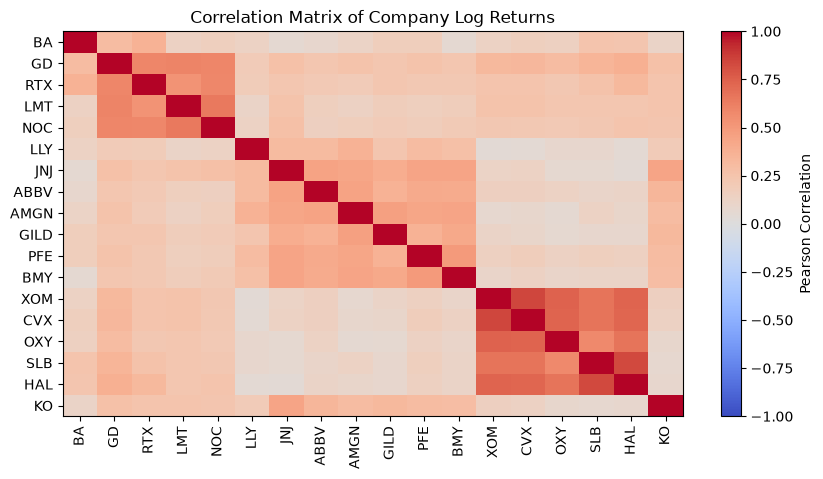

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(return_correlations.to_numpy(), aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(return_correlations.columns)))
ax.set_xticklabels(return_correlations.columns, rotation=90)

ax.set_yticks(range(len(return_correlations.index)))
ax.set_yticklabels(return_correlations.index)

ax.set_title("Correlation Matrix of Company Log Returns")
fig.colorbar(image, ax=ax, label="Pearson Correlation")
plt.show()

In [52]:
return_correlations = log_returns.corr()

company_names = {
    "BA": "Boeing",
    "GD": "General Dynamics",
    "RTX": "RTX Corporation",
    "LMT": "Lockheed Martin",
    "NOC": "Northrop Grumman",
    "LLY": "Eli Lilly",
    "JNJ": "Johnson & Johnson",
    "ABBV": "AbbVie",
    "AMGN": "Amgen",
    "GILD": "Gilead Sciences",
    "PFE": "Pfizer",
    "BMY": "Bristol Myers Squibb",
    "XOM": "Exxon Mobil",
    "CVX": "Chevron",
    "OXY": "Occidental Petroleum",
    "SLB": "SLB",
    "HAL": "Halliburton",
    "KO": "Coca-Cola"}

return_correlations = return_correlations.rename(index=company_names, columns=company_names)

upper_triangle = np.triu(np.ones(return_correlations.shape, dtype=bool), k=1)

correlation_pairs = return_correlations.where(upper_triangle).stack()

sorted_correlations = correlation_pairs.sort_values(ascending=False)

print("TOP 10 STRONGEST POSITIVE CORRELATIONS")
print(sorted_correlations.head(10).to_string())

print("\nTOP 10 STRONGEST NEGATIVE CORRELATIONS")
print(sorted_correlations.tail(10).sort_values().to_string())

TOP 10 STRONGEST POSITIVE CORRELATIONS
Ticker                Ticker              
Exxon Mobil           Chevron                 0.841723
SLB                   Halliburton             0.831682
Exxon Mobil           Occidental Petroleum    0.735068
                      Halliburton             0.733142
Chevron               Occidental Petroleum    0.729246
                      Halliburton             0.725995
Occidental Petroleum  Halliburton             0.670505
Exxon Mobil           SLB                     0.668178
Chevron               SLB                     0.665895
Lockheed Martin       Northrop Grumman        0.646593

TOP 10 STRONGEST NEGATIVE CORRELATIONS
Ticker     Ticker              
Coca-Cola  Amgen                  NaN
           Gilead Sciences        NaN
           Pfizer                 NaN
           Bristol Myers Squibb   NaN
           Exxon Mobil            NaN
           Chevron                NaN
           Occidental Petroleum   NaN
           SLB                

In [54]:
output_file = "Financial_Analysis_Results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    return_correlations.to_excel(writer, sheet_name="Correlation Matrix")

    correlation_pairs.rename("Correlation").to_frame().to_excel(writer, sheet_name="All Correlations")

    sorted_correlations.head(10).rename("Correlation").to_frame().to_excel(writer, sheet_name="Top Positive")

    sorted_correlations.tail(10).sort_values().rename("Correlation").to_frame().to_excel(writer, sheet_name="Top Negative")

print(f"Analysis completed. Results saved to {output_file}")

Analysis completed. Results saved to Financial_Analysis_Results.xlsx


In [57]:
# The correlation results show that the selected companies generally have positive relationships in their daily returns, particularly those in the energy industry. Exxon Mobil and Chevron recorded the strongest positive correlation of 0.841723, followed by SLB and Halliburton at 0.831682. Lockheed Martin and Northrop Grumman also showed a positive correlation of 0.646593.
#These results suggest that companies within the same industry tend to move in similar directions, possibly due to shared market conditions. However, the negative correlation results displayed NaN, meaning valid negative correlations were not obtained from the output.
#Conclusion: Energy companies exhibited the strongest positive relationships in their returns.